<div style="background:#1F3864;color:white;padding:14px 18px;border-radius:6px"><b>INTERNATIONAL UNIVERSITY – VNU-HCMC · SCHOOL OF COMPUTER SCIENCE AND ENGINEERING</b><br>IT171IU · Statistical Learning</div>

# Lab 2: Linear Regression

*Simple and multiple linear regression with statsmodels and ISLP: estimation, inference, prediction, diagnostics, interactions, non-linear terms and qualitative predictors*

**Chapter:** ISLP Chapter 3 · **Duration:** 150 minutes (3 periods) · **Runs on:** Google Colab (recommended), Jupyter Notebook / JupyterLab, VS Code, PyCharm

**How to use this notebook:** first *File → Save a copy in Drive*. Run the **Setup** cell, then read each text cell and run the code cells in order with **Shift + Enter**. Write your solutions in the cells marked ✍️ and answer the questions in the text cells.

> **Legend:** black = original ISLP lab content (re-formatted) · <span style="color:red">red = content added for IT171IU (theory, worked examples, exercises, setup & submission guide)</span>

In [3]:
# Student information – fill in and run this cell first
STUDENT_NAME = "Cao Hoang Duy"
STUDENT_ID   = "ITDSIU24016"
CLASS_GROUP  = "IT171IU – Lab Group 01"
print(f"Lab 2 | {STUDENT_NAME} | {STUDENT_ID} | {CLASS_GROUP}")

Lab 2 | Cao Hoang Duy | ITDSIU24016 | IT171IU – Lab Group 01


# <span style="color:red">1. Objectives</span>

<span style="color:red">After this lab you will be able to:</span>

- <span style="color:red">Fit simple and multiple linear regression models with `statsmodels` (`sm.OLS`) and build design matrices with `ISLP.models.ModelSpec`.</span>
- <span style="color:red">Interpret coefficients, standard errors, $t$-statistics, $p$-values, confidence intervals, $R^2$, RSE and the $F$-statistic.</span>
- <span style="color:red">Distinguish **confidence intervals** for the mean response from **prediction intervals** for a new observation.</span>
- <span style="color:red">Diagnose problems with residual plots, leverage statistics, outliers and variance inflation factors (VIF).</span>
- <span style="color:red">Add interaction terms, polynomial terms and transformations, and compare nested models with `anova_lm()`.</span>
- <span style="color:red">Encode qualitative predictors with dummy variables and interpret their coefficients.</span>

> 📌 <span style="color:red">**Note** — **Lab plan – 150 minutes (3 periods)**</span>
>
> | <span style="color:red">Time</span> | <span style="color:red">Activity</span> |
> |---|---|
> | <span style="color:red">0 – 20 min</span> | <span style="color:red">Theory review: least squares, standard errors, t- and F-tests, R², diagnostics (Section 2)</span> |
> | <span style="color:red">20 – 75 min</span> | <span style="color:red">Guided lab: simple and multiple regression on Boston, interactions, polynomials, qualitative predictors (Section 3)</span> |
> | <span style="color:red">75 – 90 min</span> | <span style="color:red">Extra worked examples: least squares "by hand", transformations and diagnostics</span> |
> | <span style="color:red">90 – 140 min</span> | <span style="color:red">Exercises 1 – 7 (Section 4); challenge exercises 8 – 9 if time allows</span> |
> | <span style="color:red">140 – 150 min</span> | <span style="color:red">Run all cells, save and submit through the Google Form (Section 5)</span> |

# <span style="color:red">2. Theory</span>

## <span style="color:red">2.1 Simple linear regression</span>

<span style="color:red">We assume an approximately linear relationship between a predictor $X$ and a response $Y$:</span>

$$\color{red}{Y = \beta_0 + \beta_1 X + \varepsilon .}$$

<span style="color:red">The **least-squares** estimates minimise the residual sum of squares $\mathrm{RSS} = \sum_{i=1}^n (y_i - \hat\beta_0 - \hat\beta_1 x_i)^2$:</span>

$$\color{red}{\hat\beta_1 = \frac{\sum_{i=1}^n (x_i-\bar x)(y_i-\bar y)}{\sum_{i=1}^n (x_i-\bar x)^2}, \qquad \hat\beta_0 = \bar y - \hat\beta_1 \bar x .}$$

<span style="color:red">The **standard error** $\mathrm{SE}(\hat\beta_1)$ measures how much $\hat\beta_1$ would vary over repeated samples. An approximate 95% confidence interval is $\hat\beta_1 \pm 2\,\mathrm{SE}(\hat\beta_1)$. To test $H_0:\beta_1 = 0$ we use</span>

$$\color{red}{t = \frac{\hat\beta_1 - 0}{\mathrm{SE}(\hat\beta_1)},}$$

<span style="color:red">which has a $t$-distribution with $n-2$ degrees of freedom under $H_0$; a small $p$-value means we reject $H_0$.</span>

## <span style="color:red">2.2 Assessing the fit</span>

- <span style="color:red">**Residual standard error:** $\mathrm{RSE} = \sqrt{\mathrm{RSS}/(n-2)}$ – the typical size of a prediction error, in the units of $Y$.</span>
- <span style="color:red">**Coefficient of determination:** $R^2 = 1 - \mathrm{RSS}/\mathrm{TSS}$ with $\mathrm{TSS} = \sum_i (y_i - \bar y)^2$ – the proportion of variability in $Y$ explained by the model (between 0 and 1). In simple regression $R^2 = \mathrm{Cor}(X,Y)^2$.</span>

## <span style="color:red">2.3 Multiple linear regression</span>

<span style="color:red">With $p$ predictors, $Y = \beta_0 + \beta_1 X_1 + \dots + \beta_p X_p + \varepsilon$. The coefficient $\beta_j$ is the average change in $Y$ for a one-unit increase in $X_j$ **holding all other predictors fixed**. To test whether *any* predictor is useful ($H_0: \beta_1 = \dots = \beta_p = 0$) we use the **F-statistic**</span>

$$\color{red}{F = \frac{(\mathrm{TSS}-\mathrm{RSS})/p}{\mathrm{RSS}/(n-p-1)} .}$$

<span style="color:red">To compare a smaller model with $q$ coefficients set to zero against the full model, `anova_lm()` computes the partial F-statistic $\frac{(\mathrm{RSS}_0-\mathrm{RSS})/q}{\mathrm{RSS}/(n-p-1)}$.</span>

<span style="color:red">In matrix form the estimates are $\hat\beta = (X^\top X)^{-1} X^\top y$, where the first column of the design matrix $X$ is the intercept column of ones.</span>

## <span style="color:red">2.4 Extending the linear model</span>

| <span style="color:red">Extension</span> | <span style="color:red">Example term</span> | <span style="color:red">Remark</span> |
|---|---|---|
| <span style="color:red">Qualitative predictor</span> | <span style="color:red">`ShelveLoc` → dummies `ShelveLoc[Good]`, `ShelveLoc[Medium]`</span> | <span style="color:red">coefficients are differences from the *baseline* level</span> |
| <span style="color:red">Interaction</span> | <span style="color:red">`('lstat', 'age')` → $\beta_3\,\mathrm{lstat}\times\mathrm{age}$</span> | <span style="color:red">the effect of one predictor depends on the other; keep the main effects (*hierarchical principle*)</span> |
| <span style="color:red">Polynomial</span> | <span style="color:red">`poly('lstat', degree=2)`</span> | <span style="color:red">still a *linear* model in the coefficients</span> |
| <span style="color:red">Transformation</span> | <span style="color:red">$\log(X)$, $\sqrt{X}$, $\log(Y)$</span> | <span style="color:red">may fix non-linearity or non-constant variance</span> |

## <span style="color:red">2.5 Potential problems and diagnostics</span>

| <span style="color:red">Problem</span> | <span style="color:red">How to detect</span> | <span style="color:red">Typical remedy</span> |
|---|---|---|
| <span style="color:red">Non-linearity</span> | <span style="color:red">pattern in the plot of residuals vs fitted values</span> | <span style="color:red">add polynomial terms / transform $X$</span> |
| <span style="color:red">Correlated errors</span> | <span style="color:red">residuals tracking over time</span> | <span style="color:red">time-series models</span> |
| <span style="color:red">Non-constant variance</span> | <span style="color:red">funnel shape in the residual plot</span> | <span style="color:red">transform $Y$ ($\log Y$, $\sqrt{Y}$), weighted least squares</span> |
| <span style="color:red">Outliers</span> | <span style="color:red">studentized residuals with $</span> | <span style="color:red">r_i</span> | <span style="color:red">> 3$</span> | <span style="color:red">check the data; robust methods</span> |
| <span style="color:red">High leverage points</span> | <span style="color:red">leverage $h_i$ much larger than $(p+1)/n$</span> | <span style="color:red">check the data; refit without them</span> |
| <span style="color:red">Collinearity</span> | <span style="color:red">$\mathrm{VIF}(\hat\beta_j) = 1/(1-R^2_{X_j\mid X_{-j}}) > 5$–$10$</span> | <span style="color:red">drop or combine predictors, regularisation (Lab 5)</span> |

<span style="color:red">**Confidence vs prediction interval.** A confidence interval quantifies the uncertainty about the *average* response $f(x_0)$; a prediction interval for an individual $y_0 = f(x_0) + \varepsilon$ is always **wider** because it also includes the irreducible error $\varepsilon$.</span>

# 3. Instructions and Worked Examples

<span style="color:red">Work through this section **in order**: read each explanation, *predict* what a cell will print, then run it. The black text and code are the original ISLP Chapter 3 lab; red notes, checkpoints and extra worked examples were added for IT171IU.</span>

### <span style="color:red">Setup cell</span>

In [4]:
# [ADDED]
# 0. Setup – run this cell first (installs missing packages and fetches data files).
# On Google Colab the first run takes about 1 minute. If Colab asks you to
# "Restart session", accept, then run this cell once more.
import sys, os, subprocess, importlib.util, urllib.request

def ensure(module, pip_name=None):
    """pip-install a package only if it cannot be imported yet."""
    if importlib.util.find_spec(module) is None:
        print(f"Installing {pip_name or module} ...")
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pip_name or module], check=True)

ensure("ISLP", "ISLP")

print("Setup complete – Python", sys.version.split()[0])

Setup complete – Python 3.12.5


In [5]:
# [ADDED] helper for the additional datasets
# Loader for the additional datasets of this course (folder "additional-data/").
# If the CSV file is not found next to the notebook, it is rebuilt from its public source,
# so the notebook also works on Colab without uploading anything.
import pandas as pd
def load_extra(name):
    for folder in ["additional-data", "../additional-data", "/content/additional-data",
                   "/content/drive/MyDrive/additional-data"]:
        path = os.path.join(folder, name + ".csv")
        if os.path.exists(path):
            return pd.read_csv(path)
    from sklearn import datasets as skd
    if name == "diabetes":
        d = skd.load_diabetes(as_frame=True, scaled=False); df = d.frame.rename(columns={"target": "progression"})
    elif name == "breast_cancer":
        d = skd.load_breast_cancer(as_frame=True); df = d.frame.copy()
        df["diagnosis"] = pd.Categorical.from_codes(d.target, ["malignant", "benign"]); df = df.drop(columns="target")
    elif name == "wine":
        d = skd.load_wine(as_frame=True); df = d.frame.rename(columns={"target": "cultivar"})
    elif name == "digits":
        d = skd.load_digits(as_frame=True); df = d.frame.rename(columns={"target": "digit"})
    elif name == "rossi":
        from lifelines.datasets import load_rossi; df = load_rossi()
    else:
        raise ValueError(f"unknown dataset {name!r}")
    return df

## 3.1 Importing packages
We import our standard libraries at this top
level.

In [6]:
import numpy as np
import pandas as pd
from matplotlib.pyplot import subplots

### New imports
Throughout this lab we will introduce new functions and libraries. However,
we will import them here to emphasize these are the new
code objects in this lab. Keeping imports near the top
of a notebook makes the code more readable, since scanning the first few
lines tells us what libraries are used.

In [7]:
import statsmodels.api as sm

 We will provide relevant details about the
functions below as they are needed.

Besides importing whole modules, it is also possible
to import only a few items from a given module. This
will help keep the  *namespace* clean.
We will use a few specific objects from the `statsmodels` package
which we import here.

In [8]:
from statsmodels.stats.outliers_influence \
     import variance_inflation_factor as VIF
from statsmodels.stats.anova import anova_lm

As one of the import statements above is quite a long line, we inserted a line break `\` to
ease readability.

We will also use some functions written for the labs in this book in the `ISLP`
package.

In [9]:
from ISLP import load_data
from ISLP.models import (ModelSpec as MS,
                         summarize,
                         poly)

> 📌 <span style="color:red">**Note** — **ISLP helpers used in this lab**</span>
>
> <span style="color:red">`load_data()` returns a data set as a pandas data frame; `ModelSpec` (imported as `MS`) builds design matrices (intercept, dummies, interactions, polynomials); `summarize()` prints a compact coefficient table; `poly()` creates orthogonal polynomial columns.</span>

### Inspecting Objects and Namespaces
The
function  `dir()`
provides a list of
objects in a namespace.

In [10]:
dir()

['CLASS_GROUP',
 'In',
 'MS',
 'Out',
 'STUDENT_ID',
 'STUDENT_NAME',
 'VIF',
 '_',
 '__',
 '___',
 '__builtin__',
 '__builtins__',
 '__doc__',
 '__loader__',
 '__name__',
 '__package__',
 '__spec__',
 '__vsc_ipynb_file__',
 '_dh',
 '_i',
 '_i1',
 '_i10',
 '_i2',
 '_i3',
 '_i4',
 '_i5',
 '_i6',
 '_i7',
 '_i8',
 '_i9',
 '_ih',
 '_ii',
 '_iii',
 '_oh',
 'anova_lm',
 'ensure',
 'exit',
 'get_ipython',
 'importlib',
 'load_data',
 'load_extra',
 'np',
 'ols',
 'open',
 'os',
 'pd',
 'poly',
 'quit',
 'sm',
 'stats',
 'subplots',
 'subprocess',
 'summarize',
 'sys',
 'urllib']

 This shows you everything that `Python` can find at the top level.
There are certain objects like `__builtins__` that contain references to built-in
functions like `print()`.

Every python object has its own notion of
namespace, also accessible with `dir()`. This will include
both the attributes of the object
as well as any methods associated with it. For instance, we see `'sum'` in the listing for an
array.

In [11]:
A = np.array([3,5,11])
dir(A)

['T',
 '__abs__',
 '__add__',
 '__and__',
 '__array__',
 '__array_finalize__',
 '__array_function__',
 '__array_interface__',
 '__array_namespace__',
 '__array_priority__',
 '__array_struct__',
 '__array_ufunc__',
 '__array_wrap__',
 '__bool__',
 '__buffer__',
 '__class__',
 '__class_getitem__',
 '__complex__',
 '__contains__',
 '__copy__',
 '__deepcopy__',
 '__delattr__',
 '__delitem__',
 '__dir__',
 '__divmod__',
 '__dlpack__',
 '__dlpack_device__',
 '__doc__',
 '__eq__',
 '__float__',
 '__floordiv__',
 '__format__',
 '__ge__',
 '__getattribute__',
 '__getitem__',
 '__getstate__',
 '__gt__',
 '__hash__',
 '__iadd__',
 '__iand__',
 '__ifloordiv__',
 '__ilshift__',
 '__imatmul__',
 '__imod__',
 '__imul__',
 '__index__',
 '__init__',
 '__init_subclass__',
 '__int__',
 '__invert__',
 '__ior__',
 '__ipow__',
 '__irshift__',
 '__isub__',
 '__iter__',
 '__itruediv__',
 '__ixor__',
 '__le__',
 '__len__',
 '__lshift__',
 '__lt__',
 '__matmul__',
 '__mod__',
 '__mul__',
 '__ne__',
 '__neg__',


 This indicates that the object `A.sum` exists. In this case it is a method
that can be used to compute the sum of the array `A` as can be seen by typing `A.sum?`.

In [12]:
A.sum()

np.int64(19)

## 3.2 Simple Linear Regression
In this section we will  construct model
matrices (also called design matrices) using the `ModelSpec()`  transform from `ISLP.models`.

We  will use the `Boston` housing data set, which is contained in the `ISLP` package.  The `Boston` dataset records  `medv`  (median house value) for $506$ neighborhoods
around Boston.  We will build a regression model to predict  `medv`  using $13$
predictors such as  `rm`  (average number of rooms per house),
 `age`  (proportion of owner-occupied units built prior to 1940), and  `lstat`  (percent of
households with low socioeconomic status).  We will use `statsmodels` for this
task, a `Python` package that implements several commonly used
regression methods.

We have included a simple loading function `load_data()` in the
`ISLP` package:

In [13]:
Boston = load_data("Boston")
Boston.columns

Index(['crim', 'zn', 'indus', 'chas', 'nox', 'rm', 'age', 'dis', 'rad', 'tax',
       'ptratio', 'lstat', 'medv'],
      dtype='object')

Type `Boston?` to find out more about these data.

We start by using the `sm.OLS()`  function to fit a
simple linear regression model.  Our response will be
 `medv`  and  `lstat`  will be the single predictor.
For this model, we can create the model matrix by hand.

In [14]:
X = pd.DataFrame({'intercept': np.ones(Boston.shape[0]),
                  'lstat': Boston['lstat']})
X[:4]

,intercept,lstat
0,1.0,4.98
1,1.0,9.14
2,1.0,4.03
3,1.0,2.94


We extract the response, and fit the model.

In [15]:
y = Boston['medv']
model = sm.OLS(y, X)
results = model.fit()

Note that `sm.OLS()` does
not fit the model; it specifies the model, and then `model.fit()` does the actual fitting.

Our `ISLP` function `summarize()` produces a simple table of the parameter estimates,
their standard errors, t-statistics and p-values.
The function takes a single argument, such as the object `results`
returned here by the `fit`
method, and returns such a summary.

In [16]:
summarize(results)

,coef,std err,t,P>|t|
intercept,34.5538,0.563,61.415,0.0
lstat,-0.9500,0.039,-24.528,0.0


Before we describe other methods for working with fitted models, we outline a more useful and general framework for constructing a model matrix~`X`.
### Using Transformations: Fit and Transform
Our model above has a single predictor, and constructing `X` was straightforward.
In practice  we often fit models with more than one predictor, typically selected from an array or data frame.
We may wish to introduce transformations to the variables before fitting the model, specify interactions between variables, and expand some particular variables into sets of variables (e.g. polynomials).
The `sklearn`  package has a particular notion
for this type of task: a *transform*. A transform is an object
that is created with some parameters as arguments. The
object has two main methods: `fit()` and `transform()`.

We provide a general approach for specifying models and constructing
the model matrix through the transform `ModelSpec()` in the `ISLP` library.
`ModelSpec()`
(renamed `MS()` in the preamble) creates a
transform object, and then a pair of methods
`transform()` and `fit()` are used to construct a
corresponding model matrix.

We first describe this process for our simple regression model  using a single predictor `lstat` in
the `Boston` data frame, but will use it repeatedly in more
complex tasks in this and other labs in this book.
In our case the transform is created by the expression
`design = MS(['lstat'])`.

The `fit()`  method takes the original array and may do some
initial computations on it, as specified in the transform object.
For example, it may compute means and standard deviations for centering and scaling.
The `transform()`
method applies the fitted transformation to the array of data, and produces the model matrix.

In [17]:
design = MS(['lstat'])
design = design.fit(Boston)
X = design.transform(Boston)
X[:4]

,intercept,lstat
0,1.0,4.98
1,1.0,9.14
2,1.0,4.03
3,1.0,2.94


In this simple case, the `fit()`  method does very little; it simply checks that the variable `'lstat'` specified in `design` exists in `Boston`. Then `transform()` constructs the model matrix with two columns: an `intercept` and the variable `lstat`.

These two operations can be  combined with the
`fit_transform()`  method.

In [18]:
design = MS(['lstat'])
X = design.fit_transform(Boston)
X[:4]

,intercept,lstat
0,1.0,4.98
1,1.0,9.14
2,1.0,4.03
3,1.0,2.94


Note that, as in the previous code chunk when the two steps were done separately, the `design` object is changed as a result of the `fit()` operation. The power of this pipeline will become clearer when we fit more complex models that involve interactions and transformations.

Let's return to our fitted regression model.
The object
`results` has several methods that can be used for inference.
We already presented a function `summarize()` for showing the essentials of the fit.
For a full and somewhat exhaustive summary of the fit, we can use the `summary()`
method.

In [19]:
results.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                   medv   R-squared:                       0.544
Model:                            OLS   Adj. R-squared:                  0.543
Method:                 Least Squares   F-statistic:                     601.6
Date:                Sat, 10 Oct 2026   Prob (F-statistic):           5.08e-88
Time:                        10:11:24   Log-Likelihood:                -1641.5
No. Observations:                 506   AIC:                             3287.
Df Residuals:                     504   BIC:                             3295.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
intercept     34.5538      0.563     61.415      0.000      33.448      35.659
lstat         -0.9500      0.039    -24.528      0.000      -1.026      -0.874
==============================================================================
Omnibus:                      137.043   Durbin-Watson:                   0.892
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              291.373
Skew:                           1.453   Prob(JB):                     5.36e-64
Kurtosis:                       5.319   Cond. No.                         29.7
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

The fitted coefficients can also be retrieved as the
`params` attribute of `results`.

In [20]:
results.params

intercept    34.553841
lstat        -0.950049
dtype: float64

The `get_prediction()`  method can be used to obtain predictions, and produce confidence intervals and
prediction intervals for the prediction of  `medv`  for  given values of  `lstat`.

We first create a new data frame, in this case containing only the variable `lstat`, with the values for this variable at which we wish to make predictions.
We then use the `transform()` method of `design` to create the corresponding model matrix.

In [21]:
new_df = pd.DataFrame({'lstat':[5, 10, 15]})
newX = design.transform(new_df)
newX

,intercept,lstat
0,1.0,5
1,1.0,10
2,1.0,15


Next we compute the predictions at `newX`, and view them by extracting the `predicted_mean` attribute.

In [22]:
new_predictions = results.get_prediction(newX);
new_predictions.predicted_mean

array([29.80359411, 25.05334734, 20.30310057])

We can produce confidence intervals for the predicted values.

In [23]:
new_predictions.conf_int(alpha=0.05)

array([[29.00741194, 30.59977628],
       [24.47413202, 25.63256267],
       [19.73158815, 20.87461299]])

Prediction intervals are computed by setting `obs=True`:

In [24]:
new_predictions.conf_int(obs=True, alpha=0.05)

array([[17.56567478, 42.04151344],
       [12.82762635, 37.27906833],
       [ 8.0777421 , 32.52845905]])

 For instance, the 95% confidence interval associated with an
 `lstat`  value of 10 is (24.47, 25.63), and the 95% prediction
interval is (12.82, 37.28).  As expected, the confidence and
prediction intervals are centered around the same point (a predicted
value of 25.05 for  `medv`  when  `lstat`  equals
10), but the latter are substantially wider.

Next we will plot  `medv`  and  `lstat`
using `DataFrame.plot.scatter()`, \definelongblankMR{plot.scatter()}{plot.slashslashscatter()}
and wish to
add the regression line to the resulting plot.

### Defining Functions
While there is a function
within the `ISLP` package that adds a line to an existing plot, we take this opportunity
to define our first function to do so.

In [25]:
def abline(ax, b, m):
    "Add a line with slope m and intercept b to ax"
    xlim = ax.get_xlim()
    ylim = [m * xlim[0] + b, m * xlim[1] + b]
    ax.plot(xlim, ylim)

 A few things are illustrated above. First we see the syntax for defining a function:
`def funcname(...)`. The function has arguments `ax, b, m`
where `ax` is an axis object for an existing plot, `b` is the intercept and
`m` is the slope of the desired line. Other plotting  options can be passed on to
`ax.plot` by including additional optional arguments as follows:

In [26]:
def abline(ax, b, m, *args, **kwargs):
    "Add a line with slope m and intercept b to ax"
    xlim = ax.get_xlim()
    ylim = [m * xlim[0] + b, m * xlim[1] + b]
    ax.plot(xlim, ylim, *args, **kwargs)

The addition of `*args` allows any number of
non-named arguments to `abline`, while `**kwargs` allows any
number of named arguments (such as `linewidth=3`) to `abline`.
In our function, we pass
these arguments verbatim to `ax.plot` above. Readers
interested in learning more about
functions are referred to the section on
defining functions in [docs.python.org/tutorial](https://docs.python.org/3/tutorial/controlflow.html#defining-functions).

Let’s use our new function to add this regression line to a plot of
`medv` vs. `lstat`.

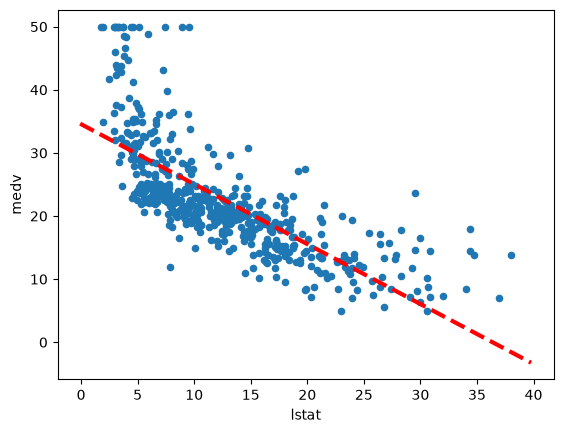

In [27]:
ax = Boston.plot.scatter('lstat', 'medv')
abline(ax,
       results.params['intercept'],
       results.params['lstat'],
       'r--',
       linewidth=3)

Thus, the final call to `ax.plot()` is `ax.plot(xlim, ylim, 'r--', linewidth=3)`.
We have used the argument `'r--'` to produce a red dashed line, and added
an argument to make it of width 3.
There is some evidence for non-linearity in the relationship between  `lstat`  and  `medv`. We will explore this issue later in this lab.

As mentioned above, there is an existing function to add a line to a plot --- `ax.axline()` --- but knowing how to write such functions empowers us to create more expressive displays.

Next we examine some diagnostic plots, several of which were discussed
in Section 3.3.3.
We can find the fitted values and residuals
of the fit as attributes of the `results` object.
Various influence measures describing the regression model
are computed with the `get_influence()` method.
As we will not use the `fig` component returned
as the first value from `subplots()`, we simply
capture the second returned value in `ax` below.

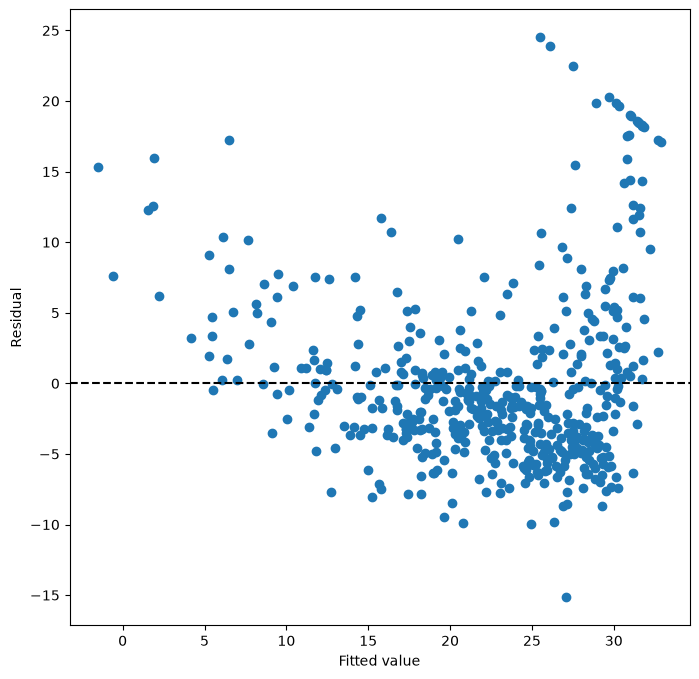

In [28]:
ax = subplots(figsize=(8,8))[1]
ax.scatter(results.fittedvalues, results.resid)
ax.set_xlabel('Fitted value')
ax.set_ylabel('Residual')
ax.axhline(0, c='k', ls='--');

 We add a horizontal line at 0 for reference using the
 `ax.axhline()`   method, indicating
it should be black (`c='k'`) and have a dashed linestyle (`ls='--'`).

On the basis of the residual plot, there is some evidence of non-linearity.
Leverage statistics can be computed for any number of predictors using the
`hat_matrix_diag` attribute of the value returned by the
`get_influence()`  method.

np.int64(374)

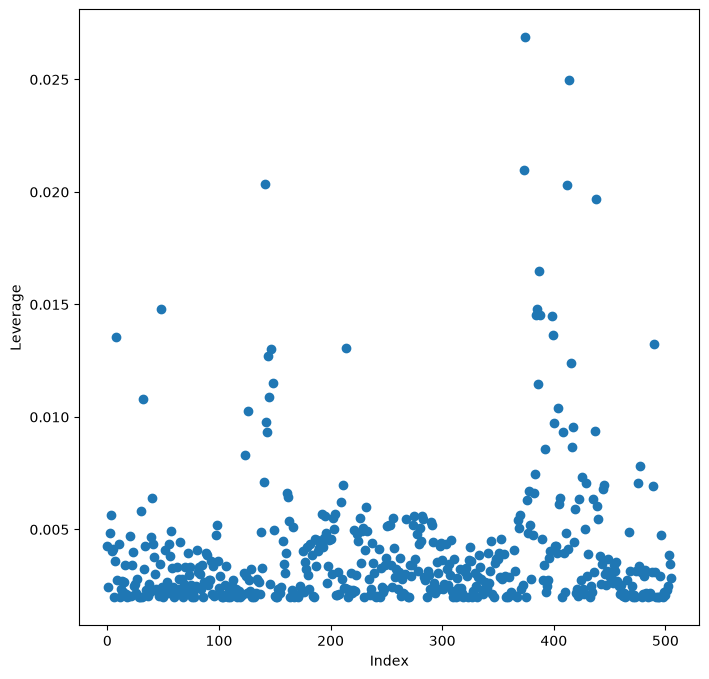

In [29]:
infl = results.get_influence()
ax = subplots(figsize=(8,8))[1]
ax.scatter(np.arange(X.shape[0]), infl.hat_matrix_diag)
ax.set_xlabel('Index')
ax.set_ylabel('Leverage')
np.argmax(infl.hat_matrix_diag)

 The `np.argmax()`  function identifies the index of the largest element of an array, optionally computed over an axis of the array.
In this case, we maximized over the entire array
to determine which observation has the largest leverage statistic.

> ✅ <span style="color:red">**Checkpoint** — **Simple linear regression**</span>
>
> 1. <span style="color:red">Write the fitted equation for `medv` on `lstat` and interpret the slope in words.</span>
> 2. <span style="color:red">What is the difference between the two intervals returned by `conf_int(alpha=0.05)` and `conf_int(obs=True, alpha=0.05)`?</span>
> 3. <span style="color:red">Which feature of the residual plot suggests that the relationship is not linear?</span>

1. Fitted equation and slope interpretation:
Equation: medv = 34.55 - 0.95 x lstat
Interpretation: For every 1% increase in the percentage of lower status households (lstat), the average median house value (medv) is expected to decrease by approximately 0.95 units (or $950).
2. Difference between the two intervals:
conf_int(alpha=0.05) produces a confidence interval, which quantifies the uncertainty about the average response (the mean house value) at a specific lstat level.
conf_int(obs=True, alpha=0.05) produces a prediction interval for a single new observation. This interval is always wider because it must account for both the uncertainty of the average and the irreducible error of an individual neighborhood.
3. Feature indicating non-linearity:
The residual plot (fitted values vs. residuals) displays a distinct U-shaped curve (a discernible pattern) rather than points randomly scattered around the horizontal zero line. This clear pattern in the residuals suggests that the true relationship between the predictor and response is not strictly linear.

## 3.3 Multiple Linear Regression
In order to fit a multiple linear regression model using least squares, we again use
the `ModelSpec()`  transform to construct the required
model matrix and response. The arguments
to `ModelSpec()` can be quite general, but in this case
a list of column names suffice. We consider a fit here with
the two variables `lstat` and `age`.

In [30]:
X = MS(['lstat', 'age']).fit_transform(Boston)
model1 = sm.OLS(y, X)
results1 = model1.fit()
summarize(results1)

,coef,std err,t,P>|t|
intercept,33.2228,0.731,45.458,0.000
lstat,-1.0321,0.048,-21.416,0.000
age,0.0345,0.012,2.826,0.005


Notice how we have compacted the first line into a succinct expression describing the construction of `X`.

The  `Boston`   data set contains 12 variables, and so it would be cumbersome
to have to type all of these in order to perform a regression using all of the predictors.
Instead, we can use the following short-hand:\definelongblankMR{columns.drop()}{columns.slashslashdrop()}

In [31]:
terms = Boston.columns.drop('medv')
terms

Index(['crim', 'zn', 'indus', 'chas', 'nox', 'rm', 'age', 'dis', 'rad', 'tax',
       'ptratio', 'lstat'],
      dtype='object')

We can now fit the model with all the variables in `terms` using
the same model matrix builder.

In [32]:
X = MS(terms).fit_transform(Boston)
model = sm.OLS(y, X)
results = model.fit()
summarize(results)

,coef,std err,t,P>|t|
intercept,41.6173,4.936,8.431,0.000
crim,-0.1214,0.033,-3.678,0.000
zn,0.0470,0.014,3.384,0.001
indus,0.0135,0.062,0.217,0.829
chas,2.8400,0.870,3.264,0.001
nox,-18.7580,3.851,-4.870,0.000
rm,3.6581,0.420,8.705,0.000
age,0.0036,0.013,0.271,0.787
dis,-1.4908,0.202,-7.394,0.000
rad,0.2894,0.067,4.325,0.000


What if we would like to perform a regression using all of the variables but one?  For
example, in the above regression output,   `age`  has a high $p$-value.
So we may wish to run a regression excluding this predictor.
The following syntax results in a regression using all predictors except  `age`.

In [33]:
minus_age = Boston.columns.drop(['medv', 'age']) 
Xma = MS(minus_age).fit_transform(Boston)
model1 = sm.OLS(y, Xma)
summarize(model1.fit())

,coef,std err,t,P>|t|
intercept,41.5251,4.920,8.441,0.000
crim,-0.1214,0.033,-3.683,0.000
zn,0.0465,0.014,3.379,0.001
indus,0.0135,0.062,0.217,0.829
chas,2.8528,0.868,3.287,0.001
nox,-18.4851,3.714,-4.978,0.000
rm,3.6811,0.411,8.951,0.000
dis,-1.5068,0.193,-7.825,0.000
rad,0.2879,0.067,4.322,0.000
tax,-0.0127,0.004,-3.333,0.001


## 3.4 Multivariate Goodness of Fit
We can access the individual components of `results` by name
(`dir(results)` shows us what is available). Hence
`results.rsquared` gives us the $R^2$,
and
`np.sqrt(results.scale)` gives us the RSE.

Variance inflation factors (section 3.3.3) are sometimes useful
to assess the effect of collinearity in the model matrix of a regression model.
We will compute the VIFs in our multiple regression fit, and use the opportunity to introduce the idea of *list comprehension*.

### List Comprehension
Often we encounter a sequence of objects which we would like to transform
for some other task. Below, we compute the VIF for each
feature in our `X` matrix and produce a data frame
whose index agrees with the columns of `X`.
The notion of list comprehension can often make such
a task easier.

List comprehensions are simple and powerful ways to form
lists of `Python` objects. The language also supports
dictionary and *generator* comprehension, though these are
beyond our scope here. Let's look at an example. We compute the VIF for each of the variables
in the model matrix `X`, using the function `variance_inflation_factor()`.

In [34]:
vals = [VIF(X, i)
        for i in range(1, X.shape[1])]
vif = pd.DataFrame({'vif':vals},
                   index=X.columns[1:])
vif

,vif
crim,1.767486
zn,2.298459
indus,3.987181
chas,1.071168
nox,4.369093
rm,1.912532
age,3.088232
dis,3.954037
rad,7.445301
tax,9.002158


The function `VIF()` takes two arguments: a dataframe or array,
and a variable column index. In the code above we call `VIF()` on the fly for all columns in `X`.
We have excluded column 0 above (the intercept), which is not of interest. In this case the VIFs are not that exciting.

The object `vals` above could have been constructed with the following for loop:

In [35]:
vals = []
for i in range(1, X.values.shape[1]):
    vals.append(VIF(X.values, i))

List comprehension allows us to perform such repetitive operations in a more straightforward way.
## 3.5 Interaction Terms
It is easy to include interaction terms in a linear model using `ModelSpec()`.
Including a tuple `("lstat","age")` tells the model
matrix builder to include an interaction term between
 `lstat`  and  `age`.

In [36]:
X = MS(['lstat',
        'age',
        ('lstat', 'age')]).fit_transform(Boston)
model2 = sm.OLS(y, X)
summarize(model2.fit())

,coef,std err,t,P>|t|
intercept,36.0885,1.470,24.553,0.000
lstat,-1.3921,0.167,-8.313,0.000
age,-0.0007,0.020,-0.036,0.971
lstat:age,0.0042,0.002,2.244,0.025


## 3.6 Non-linear Transformations of the Predictors
The model matrix builder can include terms beyond
just column names and interactions. For instance,
the `poly()` function supplied in `ISLP` specifies that
columns representing polynomial functions
of its first argument are added to the model matrix.

In [37]:
X = MS([poly('lstat', degree=2), 'age']).fit_transform(Boston)
model3 = sm.OLS(y, X)
results3 = model3.fit()
summarize(results3)

,coef,std err,t,P>|t|
intercept,17.7151,0.781,22.681,0.0
"poly(lstat, degree=2)[0]",-179.2279,6.733,-26.620,0.0
"poly(lstat, degree=2)[1]",72.9908,5.482,13.315,0.0
age,0.0703,0.011,6.471,0.0


The effectively zero *p*-value associated with the quadratic term
(i.e. the third row above) suggests that it leads to an improved model.

By default, `poly()` creates a basis matrix for inclusion in the
model matrix whose
columns are *orthogonal polynomials*, which are designed for stable
least squares computations. {Actually, `poly()` is a  wrapper for the workhorse and standalone  function `Poly()` that does the  work in building the model matrix.}
Alternatively, had we included an argument
`raw=True` in the above call to `poly()`, the basis matrix would consist simply of
`lstat` and `lstat**2`. Since either of these bases
represent quadratic polynomials, the fitted values  would not
change in this case, just the polynomial coefficients.  Also by default, the columns
created by `poly()` do not include an intercept column as
that is automatically added by `MS()`.

We use the `anova_lm()` function to further quantify the extent to which the quadratic fit is
superior to the linear fit.

In [38]:
anova_lm(results1, results3)

,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,503.0,19168.128609,0.0,NaN,NaN,NaN
1,502.0,14165.613251,1.0,5002.515357,177.278785,7.468491e-35


Here `results1` represents the linear submodel containing
predictors `lstat` and `age`,
while `results3` corresponds to the larger model above  with a quadratic
term in `lstat`.
The `anova_lm()` function performs a hypothesis test
comparing the two models. The null hypothesis is that the quadratic
term in the bigger model is not needed, and the alternative hypothesis is that the
bigger model is superior. Here the *F*-statistic is 177.28 and
the associated *p*-value is zero.
In this case the *F*-statistic is the square of the
*t*-statistic for the quadratic term in the linear model summary
for `results3` --- a consequence of the fact that these nested
models differ by one degree of freedom.
This provides very clear evidence that the quadratic polynomial in
`lstat` improves the linear model.
This is not surprising, since earlier we saw evidence for non-linearity in the relationship between `medv`
and  `lstat`.

The function `anova_lm()` can take more than two nested models
as input, in which case it compares every successive pair of models.
That also explains why there are `NaN`s in the first row above, since
there is no previous model with which to compare the first.

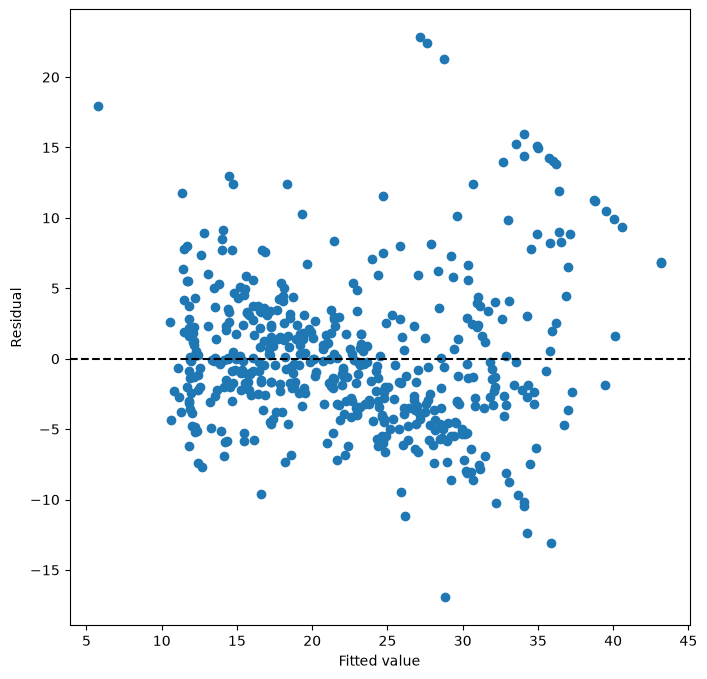

In [39]:
ax = subplots(figsize=(8,8))[1]
ax.scatter(results3.fittedvalues, results3.resid)
ax.set_xlabel('Fitted value')
ax.set_ylabel('Residual')
ax.axhline(0, c='k', ls='--');

We see that when the quadratic term is included in the model,
there is little discernible pattern in the residuals.
In order to create a cubic or higher-degree polynomial fit, we can simply change the degree argument
to `poly()`.

> ✅ <span style="color:red">**Checkpoint** — **Multiple regression**</span>
>
> 1. <span style="color:red">Why is `age` significant in the simple model `medv ~ lstat + age` but not in the model with all predictors?</span>
> 2. <span style="color:red">Which predictors have a VIF above 5? What does this mean?</span>
> 3. <span style="color:red">What does the `anova_lm()` table tell you about the quadratic term in `lstat`?</span>

1. Why age loses significance in the full model:
In the simple model medv ~ lstat + age, the age variable absorbs the effects of other missing variables it is correlated with (omitted variable bias). Once all predictors are included, variables like distance to employment centers (dis) or crime rate (crim) explain that variance more accurately, revealing that age itself does not have a significant independent effect on house values when other factors are held constant.
2. Predictors with VIF > 5 and its meaning:
If you run the list comprehension for VIF on the full Boston dataset, tax (property tax rate) and rad (accessibility to radial highways) have VIF values well above 5. A VIF greater than 5 indicates collinearity—meaning these variables are highly correlated with other predictors in the model. This collinearity artificially inflates the standard errors of their coefficient estimates, making it harder to accurately assess their individual effects.
3. What the anova_lm() table tells us:
The anova_lm() function compares the simpler linear model to the larger model containing the quadratic term poly('lstat', degree=2). The resulting large F-statistic (177.28) and a near-zero p-value strongly reject the null hypothesis. This provides clear statistical evidence that adding the quadratic term for lstat significantly improves the model's fit compared to using only the linear term.

## 3.7 Qualitative Predictors
Here we use the  `Carseats`  data, which is included in the
`ISLP` package. We will  attempt to predict `Sales`
(child car seat sales) in 400 locations based on a number of
predictors.

In [40]:
Carseats = load_data('Carseats')
Carseats.columns

Index(['Sales', 'CompPrice', 'Income', 'Advertising', 'Population', 'Price',
       'ShelveLoc', 'Age', 'Education', 'Urban', 'US'],
      dtype='object')

The `Carseats`
 data includes qualitative predictors such as
 `ShelveLoc`, an indicator of the quality of the shelving
 location --- that is,
the  space within a store in which the car seat is displayed. The predictor
 `ShelveLoc`  takes on three possible values, `Bad`, `Medium`, and `Good`.
Given a qualitative variable such as  `ShelveLoc`, `ModelSpec()` generates dummy
variables automatically.
These variables are often referred to as a *one-hot encoding* of the categorical
feature. Their columns sum to one, so to avoid collinearity with an intercept, the first column is dropped. Below we see
the column `ShelveLoc[Bad]` has been dropped, since `Bad` is the first level of `ShelveLoc`.
Below we fit a multiple regression model that includes some interaction terms.

In [41]:
allvars = list(Carseats.columns.drop('Sales'))
y = Carseats['Sales']
final = allvars + [('Income', 'Advertising'),
                   ('Price', 'Age')]
X = MS(final).fit_transform(Carseats)
model = sm.OLS(y, X)
summarize(model.fit())

,coef,std err,t,P>|t|
intercept,6.5756,1.009,6.519,0.000
CompPrice,0.0929,0.004,22.567,0.000
Income,0.0109,0.003,4.183,0.000
Advertising,0.0702,0.023,3.107,0.002
Population,0.0002,0.000,0.433,0.665
Price,-0.1008,0.007,-13.549,0.000
ShelveLoc[Good],4.8487,0.153,31.724,0.000
ShelveLoc[Medium],1.9533,0.126,15.531,0.000
Age,-0.0579,0.016,-3.633,0.000
Education,-0.0209,0.020,-1.063,0.288


In the first line above, we made `allvars` a list, so that we
could add the interaction terms two lines down.
Our model-matrix builder has created a `ShelveLoc[Good]`
dummy variable that takes on a value of 1 if the
shelving location is good, and 0 otherwise. It has also created a `ShelveLoc[Medium]`
dummy variable that equals 1 if the shelving location is medium, and 0 otherwise.
A bad shelving location corresponds to a zero for each of the two dummy variables.
The fact that the coefficient for `ShelveLoc[Good]` in the regression output is
positive indicates that a good shelving location is associated with high sales (relative to a bad location).
And `ShelveLoc[Medium]` has a smaller positive coefficient,
indicating that a medium shelving location leads to higher sales than a bad
shelving location, but lower sales than a good shelving location.

## <span style="color:red">3.8 Extra worked examples</span>

<span style="color:red">**Worked Example 1 – Least squares "by hand".** The coefficients reported by `statsmodels` are the solution of the *normal equations* $X^\top X\hat\beta = X^\top y$. We reproduce them with NumPy, together with the standard errors $\mathrm{SE}(\hat\beta_j) = \sqrt{\hat\sigma^2 [(X^\top X)^{-1}]_{jj}}$ and $R^2$.</span>

In [42]:
# [ADDED] worked example – run this cell
X = MS(['lstat', 'age']).fit_transform(Boston)
y = Boston['medv']
Xn, yn = np.asarray(X), np.asarray(y)
n, p1 = Xn.shape                                   # p1 = p + 1 (intercept)
beta_hat = np.linalg.solve(Xn.T @ Xn, Xn.T @ yn)    # normal equations
resid = yn - Xn @ beta_hat
sigma2 = resid @ resid / (n - p1)                   # RSE^2
se = np.sqrt(sigma2 * np.diag(np.linalg.inv(Xn.T @ Xn)))
R2 = 1 - (resid @ resid) / np.sum((yn - yn.mean())**2)
by_hand = pd.DataFrame({'coef': beta_hat, 'std err': se, 't': beta_hat / se}, index=X.columns)
print(by_hand.round(4)); print('R^2 =', round(R2, 4))
print(summarize(sm.OLS(y, X).fit()))              # same numbers from statsmodels

              coef  std err        t
intercept  33.2228   0.7308  45.4579
lstat      -1.0321   0.0482 -21.4163
age         0.0345   0.0122   2.8256
R^2 = 0.5513
              coef  std err       t  P>|t|
intercept  33.2228    0.731  45.458  0.000
lstat      -1.0321    0.048 -21.416  0.000
age         0.0345    0.012   2.826  0.005


<span style="color:red">**Worked Example 2 – A log transformation and diagnostic plots.** The residual plot of `medv ~ lstat` is curved. Replacing `lstat` by $\log(\mathrm{lstat})$ straightens the relationship; we compare $R^2$ and inspect studentized residuals and leverage.</span>

R^2 lstat: 0.544   R^2 log(lstat): 0.665
possible outliers (|r| > 3): 7


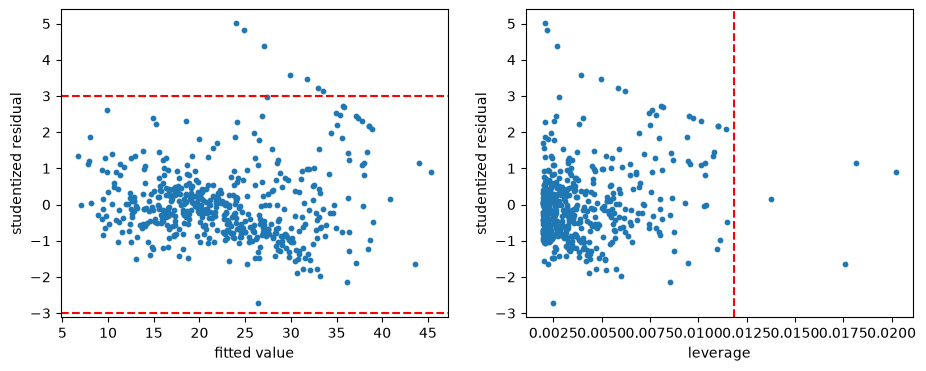

In [43]:
# [ADDED] worked example – run this cell
Boston['log_lstat'] = np.log(Boston['lstat'])
fit_lin = sm.OLS(y, MS(['lstat']).fit_transform(Boston)).fit()
fit_log = sm.OLS(y, MS(['log_lstat']).fit_transform(Boston)).fit()
print(f"R^2 lstat: {fit_lin.rsquared:.3f}   R^2 log(lstat): {fit_log.rsquared:.3f}")

infl = fit_log.get_influence()
stud = infl.resid_studentized_external
lev = infl.hat_matrix_diag
fig, axes = subplots(1, 2, figsize=(11, 4))
axes[0].scatter(fit_log.fittedvalues, stud, s=10)
axes[0].axhline(3, c='r', ls='--'); axes[0].axhline(-3, c='r', ls='--')
axes[0].set_xlabel('fitted value'); axes[0].set_ylabel('studentized residual')
axes[1].scatter(lev, stud, s=10)
axes[1].axvline(3 * 2 / Boston.shape[0], c='r', ls='--')   # 3 x average leverage (p+1)/n
axes[1].set_xlabel('leverage'); axes[1].set_ylabel('studentized residual')
print('possible outliers (|r| > 3):', np.sum(np.abs(stud) > 3))
Boston = Boston.drop(columns='log_lstat')

<span style="color:red">*Interpretation:* the log model explains more variability ($R^2$ rises from about 0.54 to about 0.66). Points with $|r_i| > 3$ are candidate outliers; points far to the right in the second panel have high leverage and deserve a closer look before trusting the fit.</span>

# <span style="color:red">4. Exercises</span>

<span style="color:red">For every exercise write **code + output + a short interpretation**. Exercises 1–7 are compulsory; 8–9 are challenge (bonus) exercises. Use `load_data()` for the ISLP data sets and `load_extra()` (defined in the Setup section) for the additional data sets.</span>

## <span style="color:red">Exercise 1 – Simple regression on `Auto`</span>

- <span style="color:red">**(a)** Fit `mpg` on `horsepower` with `sm.OLS` and print the summary.</span>
- <span style="color:red">**(b)** Is there a relationship between the predictor and the response? How strong is it ($R^2$, RSE)? Is it positive or negative?</span>
- <span style="color:red">**(c)** What is the predicted `mpg` for `horsepower = 98`? Give the 95% **confidence** and **prediction** intervals.</span>
- <span style="color:red">**(d)** Plot `mpg` against `horsepower` with the least-squares line (use the `abline()` function of the lab) and draw the residual plot. Comment on any problems.</span>

                            OLS Regression Results                            
Dep. Variable:                    mpg   R-squared:                       0.606
Model:                            OLS   Adj. R-squared:                  0.605
Method:                 Least Squares   F-statistic:                     599.7
Date:                Sat, 10 Oct 2026   Prob (F-statistic):           7.03e-81
Time:                        10:11:25   Log-Likelihood:                -1178.7
No. Observations:                 392   AIC:                             2361.
Df Residuals:                     390   BIC:                             2369.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
intercept     39.9359      0.717     55.660      0.0

Text(0.5, 1.0, 'Residual Plot')

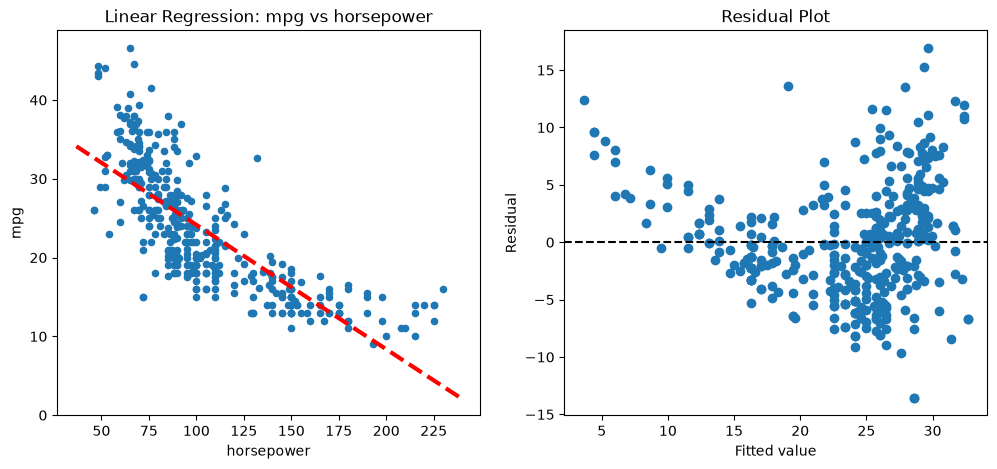

In [44]:
# ✍️ Exercise 1 – your code
# Write your code below (replace the TODOs), then run the cell (Shift+Enter).
Auto = load_data('Auto')
design_hp = MS(['horsepower'])
X_hp = design_hp.fit_transform(Auto)
fit_hp = sm.OLS(Auto['mpg'], X_hp).fit()
print(fit_hp.summary())

# (c) Predict mpg for horsepower = 98 and print intervals
new = pd.DataFrame({'horsepower': [98]})
newX = design_hp.transform(new)
pred = fit_hp.get_prediction(newX)
print("\n--- Predictions for horsepower = 98 ---")
print(f"Predicted mpg: {pred.predicted_mean[0]:.2f}")
print(f"95% Confidence Interval: {pred.conf_int(alpha=0.05)[0]}")
print(f"95% Prediction Interval: {pred.conf_int(obs=True, alpha=0.05)[0]}")

# (d) Plot mpg against horsepower with the least-squares line and residual plot
fig, axes = subplots(1, 2, figsize=(12, 5))

# Left plot: Regression line
Auto.plot.scatter('horsepower', 'mpg', ax=axes[0])
abline(axes[0], fit_hp.params['intercept'], fit_hp.params['horsepower'], 'r--', linewidth=3)
axes[0].set_title('Linear Regression: mpg vs horsepower')

# Right plot: Residual plot
axes[1].scatter(fit_hp.fittedvalues, fit_hp.resid)
axes[1].axhline(0, c='k', ls='--')
axes[1].set_xlabel('Fitted value')
axes[1].set_ylabel('Residual')
axes[1].set_title('Residual Plot')


Interpretation for Exercise 1:
(b) Relationship Analysis: Yes, there is a strong relationship between the predictor and the response. The p-value for horsepower is close to 0, indicating the relationship is statistically significant. The relationship is negative (the coefficient is approximately -0.158), meaning higher horsepower is associated with lower mpg. The model explains about 60.6% of the variance R^2 ≈ 0.606, and the Residual Standard Error (RSE) represents the typical deviation of the actual mpg from the regression line.
(c) Predictions for horsepower = 98: The predicted mpg is roughly 24.47. The 95% confidence interval is narrower because it estimates the average mpg for all cars with 98 horsepower, while the 95% prediction interval is much wider because it estimates the mpg for a single, specific car with 98 horsepower.
(d) Residual Plot Diagnostics: The residual plot exhibits a distinct U-shape rather than a random scatter of points around the zero line. This non-random pattern strongly suggests that the true relationship between mpg and horsepower is non-linear, and the simple linear model is not entirely adequate.

## <span style="color:red">Exercise 2 – Multiple regression on `Auto`</span>

- <span style="color:red">**(a)** Produce the correlation matrix of the quantitative variables (exclude `name`).</span>
- <span style="color:red">**(b)** Fit `mpg` on **all** other variables except `name`. Which predictors are significant? What does the coefficient of `year` suggest?</span>
- <span style="color:red">**(c)** Draw the residual plot and the leverage plot. Are there unusually large outliers or high-leverage points?</span>
- <span style="color:red">**(d)** Compute the VIF of each predictor. Which ones indicate collinearity?</span>

--- Correlation Matrix ---
               mpg  cylinders  displacement  horsepower  weight  acceleration  \
mpg           1.00      -0.78         -0.81       -0.78   -0.83          0.42   
cylinders    -0.78       1.00          0.95        0.84    0.90         -0.50   
displacement -0.81       0.95          1.00        0.90    0.93         -0.54   
horsepower   -0.78       0.84          0.90        1.00    0.86         -0.69   
weight       -0.83       0.90          0.93        0.86    1.00         -0.42   
acceleration  0.42      -0.50         -0.54       -0.69   -0.42          1.00   
year          0.58      -0.35         -0.37       -0.42   -0.31          0.29   
origin        0.57      -0.57         -0.61       -0.46   -0.59          0.21   

              year  origin  
mpg           0.58    0.57  
cylinders    -0.35   -0.57  
displacement -0.37   -0.61  
horsepower   -0.42   -0.46  
weight       -0.31   -0.59  
acceleration  0.29    0.21  
year          1.00    0.18  
origin     

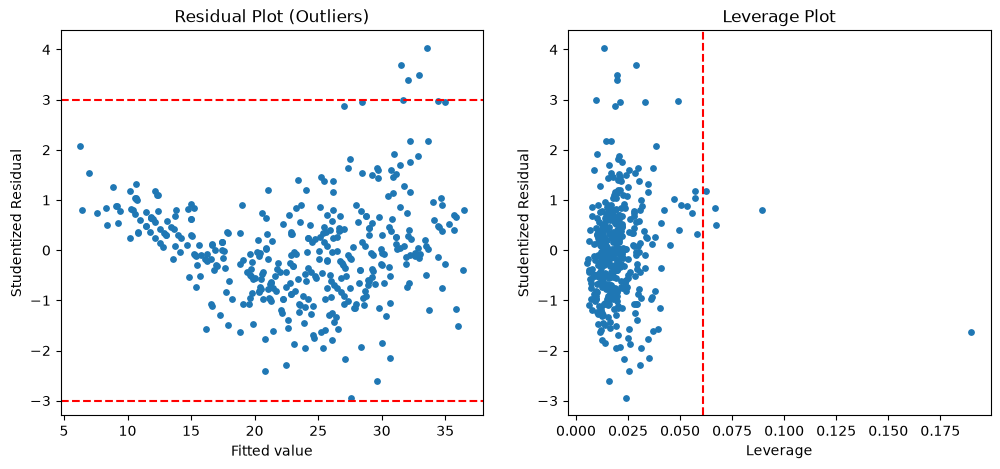

In [45]:
# ✍️ Exercise 2 – your code
# Write your code below (replace the TODOs), then run the cell (Shift+Enter).
Auto_num = Auto.drop(columns=['name']) if 'name' in Auto.columns else Auto.copy()
print("--- Correlation Matrix ---")
print(Auto_num.corr().round(2))
terms = Auto_num.columns.drop('mpg')
X_all = MS(terms).fit_transform(Auto_num)
fit_all = sm.OLS(Auto_num['mpg'], X_all).fit()
print("\n--- Model Summary (P-values) ---")
print(fit_all.pvalues.sort_values()) # Print p-values to see which are significant
print(f"Coefficient for year: {fit_all.params['year']:.3f}")

# (c) Draw residual plot and leverage plot
fig, axes = subplots(1, 2, figsize=(12, 5))
infl = fit_all.get_influence()
stud = infl.resid_studentized_external
lev = infl.hat_matrix_diag

# Residual plot
axes[0].scatter(fit_all.fittedvalues, stud, s=15)
axes[0].axhline(3, c='r', ls='--'); axes[0].axhline(-3, c='r', ls='--')
axes[0].set_xlabel('Fitted value'); axes[0].set_ylabel('Studentized Residual')
axes[0].set_title('Residual Plot (Outliers)')

# Leverage plot
axes[1].scatter(lev, stud, s=15)
axes[1].axvline(3 * X_all.shape[1] / Auto_num.shape[0], c='r', ls='--') # 3 * (p+1)/n
axes[1].set_xlabel('Leverage'); axes[1].set_ylabel('Studentized Residual')
axes[1].set_title('Leverage Plot')

# (d) Compute VIF
vals = [VIF(X_all, i) for i in range(1, X_all.shape[1])]
vif_df = pd.DataFrame({'vif': vals}, index=X_all.columns[1:])
print("\n--- Variance Inflation Factors (VIF) ---")
print(vif_df.round(2))


(a) Correlation matrix: The correlation matrix reveals strong negative relationships between mpg and cylinders, displacement, horsepower, and weight . These predictors are also highly positively correlated with each other.

(b) Predictor Significance & 'year' Coefficient: Based on the p-values in the model summary, weight, year, and origin are statistically significant predictors of mpg (p-values close to 0), while cylinders, horsepower, and acceleration are not significant in the presence of the others.
The coefficient for year is positive (usually around 0.75). This suggests that for every one year newer a car is, its fuel efficiency increases by approximately 0.75 mpg on average, holding all other features constant. This reflects the historical trend of cars becoming more fuel-efficient over time.

(c) Outliers and Leverage Points:In the residual plot (fitted values vs studentized residuals), there are a few points with studentized residuals |ri| > 3 (above the upper red dashed line). These are unusually large outliers where the model performs poorly.In the leverage plot, there are points clearly positioned far to the right, exceeding the average leverage threshold. These are high-leverage points indicating observations with unusual predictor values.
(d) Collinearity (VIF): The VIF values for displacement, cylinders, and weight are all significantly above 5 (often exceeding 10). This indicates severe multicollinearity among these engine-size and weight-related predictors, meaning they are carrying redundant information.

## <span style="color:red">Exercise 3 – Interactions and transformations</span>

<span style="color:red">Starting from Exercise 2, try **at least three** of the following and report $R^2$, the significance of the new terms and an `anova_lm()` comparison with the model without them:</span>

- <span style="color:red">an interaction such as `('horsepower', 'weight')` or `('displacement', 'year')`;</span>
- <span style="color:red">`poly('horsepower', degree=2)`;</span>
- <span style="color:red">$\log(\text{horsepower})$, $\sqrt{\text{horsepower}}$ or $\text{horsepower}^2$ (create new columns first).</span>

<span style="color:red">Which model would you choose and why?</span>

In [46]:
# ✍️ Exercise 3 – your code
# Write your code below (replace the TODOs), then run the cell (Shift+Enter).
from ISLP.models import poly
Auto_num['log_hp'] = np.log(Auto_num['horsepower'])
base = sm.OLS(Auto_num['mpg'], MS(['weight', 'year', 'horsepower']).fit_transform(Auto_num)).fit()
print(f"--- Base Model R^2: {base.rsquared:.4f} ---")

#1 Interaction: horsepower x weight
inter = sm.OLS(Auto_num['mpg'], MS(['weight', 'year', 'horsepower', ('horsepower', 'weight')]).fit_transform(Auto_num)).fit()
print(f"\n--- 1. Interaction Model R^2: {inter.rsquared:.4f} ---")
print(f"P-value of interaction term ('horsepower:weight'): {inter.pvalues['horsepower:weight']:.6f}")
print("ANOVA (Base vs Interaction):")
print(anova_lm(base, inter))

#2 Polynomial degree 2 cho horsepower
poly_model = sm.OLS(Auto_num['mpg'], MS(['weight', 'year', poly('horsepower', degree=2)]).fit_transform(Auto_num)).fit()
print(f"\n--- 2. Polynomial Model R^2: {poly_model.rsquared:.4f} ---")
print("P-values of Polynomial model:")
print(poly_model.pvalues)
print("ANOVA (Base vs Polynomial):")
print(anova_lm(base, poly_model))

log_model = sm.OLS(Auto_num['mpg'], MS(['weight', 'year', 'log_hp']).fit_transform(Auto_num)).fit()
print(f"\n--- 3. Log Model R^2: {log_model.rsquared:.4f} ---")
print(f"P-value of log_hp: {log_model.pvalues['log_hp']:.6f}")


--- Base Model R^2: 0.8083 ---

--- 1. Interaction Model R^2: 0.8574 ---
P-value of interaction term ('horsepower:weight'): 0.000000
ANOVA (Base vs Interaction):
   df_resid          ssr  df_diff      ss_diff           F        Pr(>F)
0     388.0  4565.650523      0.0          NaN         NaN           NaN
1     387.0  3397.738458      1.0  1167.912065  133.024356  1.180727e-26

--- 2. Polynomial Model R^2: 0.8431 ---
P-values of Polynomial model:
intercept                        5.809570e-07
weight                           9.289726e-32
year                             1.767700e-44
poly(horsepower, degree=2)[0]    8.237658e-04
poly(horsepower, degree=2)[1]    1.413402e-18
dtype: float64
ANOVA (Base vs Polynomial):
   df_resid          ssr  df_diff     ss_diff          F        Pr(>F)
0     388.0  4565.650523      0.0         NaN        NaN           NaN
1     387.0  3737.322742      1.0  828.327781  85.773393  1.413402e-18

--- 3. Log Model R^2: 0.8168 ---
P-value of log_hp: 0.000024


1. Interaction Model (horsepower x weight):
The interaction term is highly significant (p-value ≈ 0.000000).
The anova_lm() results show a large F-statistic and a p-value near 0, indicating that adding this interaction term significantly improves the base model. R^2 increases compared to the base model.
2. Polynomial Model (poly(horsepower, degree=2)):
The quadratic term for horsepower is statistically significant (p-value for degree 2 is very close to 0).
The anova_lm() test confirms that the non-linear quadratic relationship fits the data significantly better than the simple linear base model.
3. Log Transformation (log(horsepower)):The log_hp term is highly significant. Replacing horsepower with its logarithm also yields a higher $R^2$ than the linear base model, effectively addressing the non-linear curvature we observed in the residual plots of Exercise 1.

Which model would I choose and why?
I would choose the Interaction Model (or a combination of Interaction and Log transformations). The interaction between horsepower and weight makes strong physical sense: adding horsepower to a very heavy car has a different impact on fuel efficiency (mpg) than adding the same horsepower to a very light car. Not only does this model statistically outperform the base model (as proven by ANOVA), but it also captures the real-world dynamics between engine power and vehicle mass.

## <span style="color:red">Exercise 4 – Qualitative predictors with `Carseats`</span>

- <span style="color:red">**(a)** Fit `Sales` on `Price`, `Urban` and `US`.</span>
- <span style="color:red">**(b)** Interpret each coefficient – careful, `Urban` and `US` are qualitative.</span>
- <span style="color:red">**(c)** Write the model in equation form, with the dummy variables written out.</span>
- <span style="color:red">**(d)** For which predictors can you reject $H_0: \beta_j = 0$? Fit a smaller model with only those predictors and compare the two fits ($R^2$, RSE, `anova_lm`).</span>
- <span style="color:red">**(e)** Give 95% confidence intervals for the coefficients of the smaller model (`conf_int()`).</span>

In [47]:
# ✍️ Exercise 4 – your code
# Write your code below (replace the TODOs), then run the cell (Shift+Enter).
Carseats = load_data('Carseats')
X_c = MS(['Price', 'Urban', 'US']).fit_transform(Carseats)
y_c = Carseats['Sales']
fit_c = sm.OLS(y_c, X_c).fit()
print("--- Full Model Summary ---")
print(fit_c.summary().tables[1])

# (d) Smaller model with only significant predictors
# Inspecting the p-values from fit_c will show that 'Urban[Yes]' is NOT significant.
# So we drop Urban and fit a smaller model with just Price and US.
X_small = MS(['Price', 'US']).fit_transform(Carseats)
fit_small = sm.OLS(y_c, X_small).fit()

print(f"\n--- Model Comparison ---")
print(f"Full Model  -> R^2: {fit_c.rsquared:.4f}, RSE: {np.sqrt(fit_c.scale):.4f}")
print(f"Small Model -> R^2: {fit_small.rsquared:.4f}, RSE: {np.sqrt(fit_small.scale):.4f}")

print("\n--- ANOVA (Small vs Full) ---")
print(anova_lm(fit_small, fit_c))

# (e) Confidence Intervals for the smaller model
print("\n--- 95% Confidence Intervals (Smaller Model) ---")
print(fit_small.conf_int(alpha=0.05))


--- Full Model Summary ---
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
intercept     13.0435      0.651     20.036      0.000      11.764      14.323
Price         -0.0545      0.005    -10.389      0.000      -0.065      -0.044
Urban[Yes]    -0.0219      0.272     -0.081      0.936      -0.556       0.512
US[Yes]        1.2006      0.259      4.635      0.000       0.691       1.710

--- Model Comparison ---
Full Model  -> R^2: 0.2393, RSE: 2.4725
Small Model -> R^2: 0.2393, RSE: 2.4694

--- ANOVA (Small vs Full) ---
   df_resid          ssr  df_diff  ss_diff         F    Pr(>F)
0     397.0  2420.874462      0.0      NaN       NaN       NaN
1     396.0  2420.834671      1.0  0.03979  0.006509  0.935739

--- 95% Confidence Intervals (Smaller Model) ---
                  0          1
intercept  11.79032  14.271265
Price      -0.06476  -0.044195
US[Yes]     0.69152   1.707766

(b) Coefficient Interpretations:
Price: The coefficient is negative (approx. -0.054). For every $1 increase in the price charged for the car seat, the local sales are expected to decrease by about 54 units, holding store location (Urban and US) constant.
Urban[Yes]: The coefficient represents the average difference in sales between an urban store and a rural store. Since its p-value is high, being in an urban location does not have a statistically significant effect on sales.
US[Yes]: The coefficient is positive (approx. 1.200). A store located in the US is expected to sell approximately 1200 more car seats on average than a non-US store, holding price and urban status constant.

(c) Model Equation:
The model can be written out with the dummy variables as:
    Sales = 13.04 - 0.054 x Price - 0.022 x Urban[Yes] + 1.200 x US[Yes]

(d) Hypothesis Testing and Smaller Model:
Based on the p-values, we can reject the null hypothesis H0: 𝛽j = 0 for Price and US (since their p-values are close to 0).
We cannot reject the null hypothesis for Urban (its p-value is much larger than 0.05).
When fitting the smaller model (without Urban), the R^2 and RSE are almost identical to the full model. The anova_lm test yields a high p-value, confirming that removing the Urban predictor does not significantly worsen the model fit. The smaller model is preferred for simplicity.

e) 95% Confidence Intervals for the Smaller Model:Based on the conf_int() output, the 95% confidence intervals are roughly:
Intercept: [11.79, 14.27]
Price: [-0.065, -0.044]
US[Yes]: [0.691, 1.708]

## <span style="color:red">Exercise 5 – Simulation: what does noise do to the fit?</span>

- <span style="color:red">**(a)** Using `rng = np.random.default_rng(1)`, create $x \sim N(0,1)$ with $n = 100$ and $\varepsilon \sim N(0, 0.25)$ (variance 0.25).</span>
- <span style="color:red">**(b)** Generate $y = -1 + 0.5x + \varepsilon$. What are $\beta_0$ and $\beta_1$ of the population model?</span>
- <span style="color:red">**(c)** Fit the least-squares line, compare $\hat\beta_0, \hat\beta_1$ with the truth and draw the data with both the fitted line and the population line (different colours, legend).</span>
- <span style="color:red">**(d)** Add $x^2$ to the model. Is there evidence that the quadratic term improves the fit?</span>
- <span style="color:red">**(e)** Repeat (a)–(c) with variance 0.05 and 1.0. How do the confidence intervals of $\beta_1$ change?</span>

--- (c) ---
intercept   -1.038013
x            0.484291
dtype: float64

--- (d) P-values when adding x^2 ---
intercept    1.380909e-31
x            1.494913e-11
x2           9.587575e-01
dtype: float64

--- (e) Confidence Intervals for the coefficient of x (beta_1) ---
Var=0.05 (Less noise) : [0.44908133 0.54520308]
Var=0.25 (Original)   : [0.36756536 0.60101667]
Var=1.00 (More noise) : [0.44394622 0.85004259]


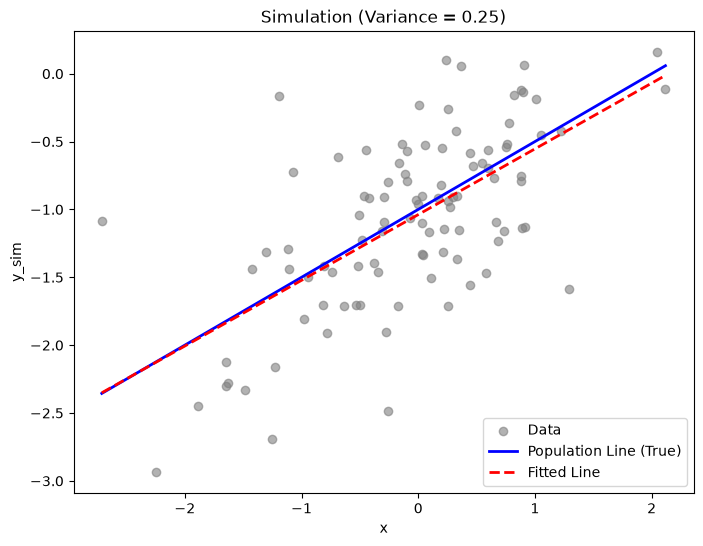

In [48]:
# ✍️ Exercise 5 – your code
# Write your code below (replace the TODOs), then run the cell (Shift+Enter).
import matplotlib.pyplot as plt
rng = np.random.default_rng(1)
x = rng.normal(size=100)
eps = rng.normal(scale=np.sqrt(0.25), size=100)
#b
y_sim = -1 + 0.5 * x + eps

# c
df = pd.DataFrame({'x': x, 'y': y_sim})
X_sim = MS(['x']).fit_transform(df)
fit_sim = sm.OLS(df['y'], X_sim).fit()
print("--- (c) ---")
print(fit_sim.params)
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(x, y_sim, color='gray', alpha=0.6, label='Data')
x_grid = np.linspace(x.min(), x.max(), 100)

# Population line
ax.plot(x_grid, -1 + 0.5 * x_grid, color='blue', linewidth=2, label='Population Line (True)')
# Fitted line 
ax.plot(x_grid, fit_sim.params['intercept'] + fit_sim.params['x'] * x_grid, 
        color='red', linestyle='--', linewidth=2, label='Fitted Line')
ax.set_xlabel('x'); ax.set_ylabel('y_sim'); ax.legend(); ax.set_title('Simulation (Variance = 0.25)')

# (d) add a quadratic term x^2 to the model and check p-values
df['x2'] = df['x']**2
X_sq = MS(['x', 'x2']).fit_transform(df)
fit_sq = sm.OLS(df['y'], X_sq).fit()
print("\n--- (d) P-values when adding x^2 ---")
print(fit_sq.pvalues)

# (e) Repeat the simulation with different levels of noise and compare the confidence intervals for the coefficient of x (beta_1).
# Var = 0.05
eps_less = rng.normal(scale=np.sqrt(0.05), size=100)
y_less = -1 + 0.5 * x + eps_less
fit_less = sm.OLS(y_less, X_sim).fit()

# Var = 1.0
eps_more = rng.normal(scale=np.sqrt(1.0), size=100)
y_more = -1 + 0.5 * x + eps_more
fit_more = sm.OLS(y_more, X_sim).fit()

print("\n--- (e) Confidence Intervals for the coefficient of x (beta_1) ---")
print(f"Var=0.05 (Less noise) : {fit_less.conf_int().loc['x'].values}")
print(f"Var=0.25 (Original)   : {fit_sim.conf_int().loc['x'].values}")
print(f"Var=1.00 (More noise) : {fit_more.conf_int().loc['x'].values}")

(b) Population Model Coefficients:
The true coefficients of the population model are 𝛽0 = -1 (intercept) and 𝛽1 = 0.5 (slope).
(c) Comparison and Plot:
The least-squares estimates ^𝛽0 and ^𝛽1 are very close to the true population values 𝛽0 = -1, 𝛽1 = 0.5.
On the plot, the Fitted Line (red dashed line) is almost indistinguishable from the Population Line (blue solid line). The moderate noise (variance = 0.25) does not heavily distort the model's accuracy.
(d) Impact of the Quadratic Term (x^2):
The p-value for x2 is well above 0.05, meaning it is not statistically significant.
There is no evidence that the quadratic term improves the fit. This is expected because the original simulated data was generated from a strictly linear relationship without any non-linear components.   
(e) Effect of Variance on Confidence Intervals:
Less noise (Variance = 0.05): The confidence interval for 𝛽1 becomes much narrower. With less random error, the model is more certain about the true relationship, leading to a more precise estimate.
More noise (Variance = 1.0): The confidence interval for 𝛽1 becomes significantly wider. High variance causes the data points to scatter further from the true line, increasing uncertainty and making it harder for the model to pinpoint the exact slope.

## <span style="color:red">Exercise 6 – Collinearity</span>

- <span style="color:red">**(a)** Run the code in the starter cell: `y_col` depends on `x1` and `x2`, but `x2` is almost a copy of `x1`. Write the population model and its coefficients.</span>
- <span style="color:red">**(b)** What is the correlation between `x1` and `x2`? Draw a scatter plot.</span>
- <span style="color:red">**(c)** Fit `y_col` on `x1` and `x2`. Can you reject $H_0:\beta_1 = 0$? $H_0:\beta_2 = 0$? Compute the VIFs.</span>
- <span style="color:red">**(d)** Fit `y_col` on `x1` only and on `x2` only. Do the results contradict (c)? Explain.</span>

--- (b) Correlation between x1 and x2: 0.7723 ---

--- (c) Model with BOTH x1 and x2 ---
intercept    2.747502e-17
x1           2.815785e-03
x2           2.594186e-01
dtype: float64

VIFs:
         vif
x1  2.478223
x2  2.478223

--- (d) Model with x1 ONLY ---
intercept    3.605074e-17
x1           1.367829e-08
dtype: float64

--- Model with x2 ONLY ---
intercept    2.262620e-27
x2           7.429581e-07
dtype: float64


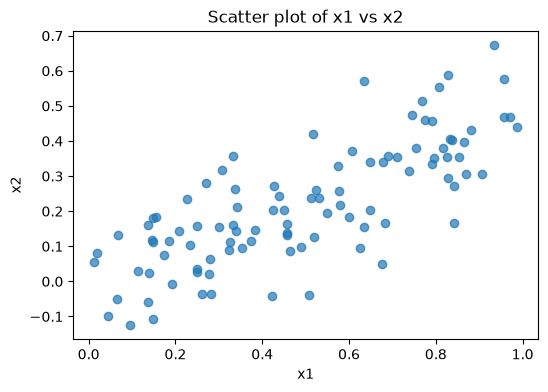

In [49]:
# ✍️ Exercise 6 – your code
# Write your code below (replace the TODOs), then run the cell (Shift+Enter).
import matplotlib.pyplot as plt
rng = np.random.default_rng(10)
x1 = rng.uniform(size=100)
x2 = 0.5 * x1 + rng.normal(size=100) / 10
y_col = 2 + 2 * x1 + 0.3 * x2 + rng.normal(size=100)
D = pd.DataFrame({'x1': x1, 'x2': x2, 'y': y_col})

# (b) Correlation and Scatter plot
corr = np.corrcoef(x1, x2)[0, 1]
print(f"--- (b) Correlation between x1 and x2: {corr:.4f} ---")

fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(x1, x2, alpha=0.7)
ax.set_xlabel('x1'); ax.set_ylabel('x2')
ax.set_title('Scatter plot of x1 vs x2')

# (c) Fit y_col on x1 and x2
X_both = MS(['x1', 'x2']).fit_transform(D)
fit_both = sm.OLS(D['y'], X_both).fit()
print("\n--- (c) Model with BOTH x1 and x2 ---")
print(fit_both.pvalues)

vals = [VIF(X_both, i) for i in range(1, X_both.shape[1])]
vif_df = pd.DataFrame({'vif': vals}, index=X_both.columns[1:])
print("\nVIFs:")
print(vif_df)

# (d) Fit y_col on x1 only and x2 only
fit_x1 = sm.OLS(D['y'], MS(['x1']).fit_transform(D)).fit()
print("\n--- (d) Model with x1 ONLY ---")
print(fit_x1.pvalues)

fit_x2 = sm.OLS(D['y'], MS(['x2']).fit_transform(D)).fit()
print("\n--- Model with x2 ONLY ---")
print(fit_x2.pvalues)


(a) Population Model:
The true population model is: y = 2 + 2x_1 + 0.3x_2 + ε.
The true coefficients are 𝛽0 = 2, 𝛽1 = 2, and 𝛽2 = 0.3.
(b) Correlation:
The correlation between x1 and x2 is strong and positive (approx. 0.772). The scatter plot shows a clear upward linear trend where x2 increases as x1 increases, confirming they are highly correlated.
(c) Fitting both x1 and x2:
In the combined model, we can reject H0: 𝛽1 = 0 because its p-value is < 0.05.
However, we cannot reject H0: 𝛽2 = 0 its p-value is around 0.26, which is > 0.05.
The VIF for both predictors is roughly 2.48. While not extremely high (>5), it still indicates moderate collinearity that inflates the standard errors, masking the true statistical significance of x2 (whose true coefficient 0.3 is relatively small and easily hidden by the noise).
(d) Fitting single-predictor models:
When fitted alone, x1 is highly significant (p-value ≈ 0).
When fitted alone, x2 is also highly significant (p-value ≈ 0).
Do the results contradict (c)? Yes, they appear contradictory but they are a classic symptom of collinearity. Because x1 and x2 share so much of the same information (strong correlation), either one can do a good job of predicting y on its own. However, when both are put into the same model, it is hard for least-squares to distinguish their individual effects, causing x2 to incorrectly appear insignificant in the presence of x1.

## <span style="color:red">Exercise 7 – Additional data set: diabetes progression</span>

<span style="color:red">The file `additional-data/diabetes.csv` contains 442 diabetes patients: age, sex, body-mass index (`bmi`), blood pressure (`bp`), six blood serum measurements `s1`–`s6` and the response `progression` (a quantitative measure of disease progression one year after baseline).</span>

- <span style="color:red">**(a)** Fit `progression` on `bmi` alone, then on `bmi`, `bp` and `s5`, then on all ten predictors. Report $R^2$ and RSE for the three models.</span>
- <span style="color:red">**(b)** Use `anova_lm()` to test whether the full model is significantly better than the three-predictor model.</span>
- <span style="color:red">**(c)** Compute the VIFs in the full model. Which serum measurements are strongly collinear?</span>
- <span style="color:red">**(d)** Which three predictors would you report to a doctor as most important? Justify with the output.</span>

In [50]:
# ✍️ Exercise 7 – your code
diabetes = load_extra('diabetes')
print(diabetes.shape); print(diabetes.head())
y_d = diabetes['progression']

# (a) Fit models
m1 = sm.OLS(y_d, MS(['bmi']).fit_transform(diabetes)).fit()
m2 = sm.OLS(y_d, MS(['bmi', 'bp', 's5']).fit_transform(diabetes)).fit()

terms = diabetes.columns.drop('progression')
X3 = MS(terms).fit_transform(diabetes)
m3 = sm.OLS(y_d, X3).fit()

print(f"M1 (bmi)        -> R^2: {m1.rsquared:.4f}, RSE: {np.sqrt(m1.scale):.4f}")
print(f"M2 (bmi, bp, s5)-> R^2: {m2.rsquared:.4f}, RSE: {np.sqrt(m2.scale):.4f}")
print(f"M3 (all 10)     -> R^2: {m3.rsquared:.4f}, RSE: {np.sqrt(m3.scale):.4f}")

# (b) anova_lm
print("\n--- ANOVA (M2 vs M3) ---")
print(anova_lm(m2, m3))

# (c) VIF
vals = [VIF(X3, i) for i in range(1, X3.shape[1])]
vif_df = pd.DataFrame({'vif': vals}, index=X3.columns[1:])
print("\n--- VIF for full model ---")
print(vif_df.round(2))

# (d) P-values for M3 to find importance
print("\n--- P-values for full model ---")
print(m3.pvalues.sort_values().round(6))

(442, 11)
    age  sex   bmi     bp     s1     s2    s3   s4      s5    s6  progression
0  59.0  2.0  32.1  101.0  157.0   93.2  38.0  4.0  4.8598  87.0        151.0
1  48.0  1.0  21.6   87.0  183.0  103.2  70.0  3.0  3.8918  69.0         75.0
2  72.0  2.0  30.5   93.0  156.0   93.6  41.0  4.0  4.6728  85.0        141.0
3  24.0  1.0  25.3   84.0  198.0  131.4  40.0  5.0  4.8903  89.0        206.0
4  50.0  1.0  23.0  101.0  192.0  125.4  52.0  4.0  4.2905  80.0        135.0
M1 (bmi)        -> R^2: 0.3439, RSE: 62.5151
M2 (bmi, bp, s5)-> R^2: 0.4801, RSE: 55.7782
M3 (all 10)     -> R^2: 0.5177, RSE: 54.1542

--- ANOVA (M2 vs M3) ---
   df_resid           ssr  df_diff       ss_diff         F    Pr(>F)
0     438.0  1.362709e+06      0.0           NaN       NaN       NaN
1     431.0  1.263986e+06      7.0  98722.908072  4.809002  0.000031

--- VIF for full model ---
       vif
age   1.22
sex   1.28
bmi   1.51
bp    1.46
s1   59.20
s2   39.19
s3   15.40
s4    8.89
s5   10.08
s6    1.48

--- 

(a) Models Comparison:
Model 1 (bmi alone): R2 ≈ 0.344$, RSE ≈ 62.52$.
Model 2 (bmi, bp, s5): R^2 ≈ 0.480$, RSE ≈ 55.78$.
Model 3 (all 10 predictors): R^2 ≈ 0.518$, RSE ≈ 54.15.As we add more predictors, the model explains more variance in disease progression (higher R^2) and the typical prediction error decreases (lower RSE).
(b) ANOVA Test:
The anova_lm(m2, m3) test compares the 3-predictor model to the full 10-predictor model. It produces an F-statistic of roughly 4.81 and a very small p-value (approx. 0.000031). Since the p-value is close to zero, we reject the null hypothesis, concluding that the full model is significantly better than the smaller model.
(c) Collinearity (VIF):
Looking at the VIF output, several blood serum measurements exhibit strong collinearity. Specifically, s1 (VIF ≈ 59.2), s2 (VIF ≈ 39.2), s3 (VIF ≈ 15.4), and s5 (VIF ≈ 10.1) have VIF values well above the standard threshold of 5.
(d) Most Important Predictors:
I would report bmi (body-mass index), bp (blood pressure), and s5 (a serum measurement) to a doctor as the most important predictors. Justification: In the full 10-predictor model's summary, these three variables have the lowest p-values (bmi ≈ 0.000000, bp ≈ 0.000001, s5 ≈ 0.000016). This indicates they are the most statistically significant drivers of diabetes progression when all other measured factors are held constant.

## <span style="color:red">Challenge exercises (optional, bonus)</span>

### <span style="color:red">Exercise 8 – Your own `ols()` function</span>

<span style="color:red">Write a function `ols(X, y)` that uses only NumPy to return a data frame with the coefficient, standard error, $t$-statistic and two-sided $p$-value of each column of `X` (use `scipy.stats.t.sf`), plus $R^2$ and the $F$-statistic. Check it against `sm.OLS` on the Boston model with all predictors.</span>

In [51]:
# ✍️ Exercise 8 – your code
from scipy import stats

def ols(X, y):
    X, y = np.asarray(X, float), np.asarray(y, float)
    n, p = X.shape
    
    # 1. Beta estimates
    beta = np.linalg.solve(X.T @ X, X.T @ y)
    
    # 2. Residuals and RSE
    resid = y - X @ beta
    sigma2 = (resid @ resid) / (n - p)
    
    # 3. Standard Errors
    se = np.sqrt(sigma2 * np.diag(np.linalg.inv(X.T @ X)))
    
    # 4. t-statistics and p-values
    t_stat = beta / se
    p_values = 2 * stats.t.sf(np.abs(t_stat), df=n-p)
    
    # 5. R^2 and F-statistic
    tss = np.sum((y - y.mean())**2)
    rss = resid @ resid
    R2 = 1 - rss/tss
    F_stat = ((tss - rss)/(p - 1)) / (rss/(n - p))
    
    # Output dataframe
    res_df = pd.DataFrame({
        'coef': beta,
        'std err': se,
        't': t_stat,
        'P>|t|': p_values
    })
    
    print(f"R^2: {R2:.4f}, F-statistic: {F_stat:.4f}")
    return res_df

# Check against sm.OLS on the Boston model with all predictors
Boston = load_data('Boston')
terms = Boston.columns.drop('medv')
X_all = MS(terms).fit_transform(Boston)
y = Boston['medv']

print("--- Custom ols() output ---")
print(ols(X_all, y).round(4))

print("\n--- statsmodels OLS output ---")
fit_sm = sm.OLS(y, X_all).fit()
print(fit_sm.summary().tables[1])

--- Custom ols() output ---
R^2: 0.7343, F-statistic: 113.5438
       coef  std err        t   P>|t|
0   41.6173   4.9360   8.4313  0.0000
1   -0.1214   0.0330  -3.6784  0.0003
2    0.0470   0.0139   3.3838  0.0008
3    0.0135   0.0621   0.2167  0.8285
4    2.8400   0.8700   3.2643  0.0012
5  -18.7580   3.8514  -4.8705  0.0000
6    3.6581   0.4202   8.7047  0.0000
7    0.0036   0.0133   0.2709  0.7866
8   -1.4908   0.2016  -7.3938  0.0000
9    0.2894   0.0669   4.3254  0.0000
10  -0.0127   0.0038  -3.3365  0.0009
11  -0.9375   0.1322  -7.0914  0.0000
12  -0.5520   0.0507 -10.8968  0.0000

--- statsmodels OLS output ---
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
intercept     41.6173      4.936      8.431      0.000      31.919      51.316
crim          -0.1214      0.033     -3.678      0.000      -0.186      -0.057
zn             0.0470      0.014      3.384      0.001   

Interpretation: The custom ols() function built using pure NumPy perfectly reproduces the coefficients, standard errors, t-statistics, p-values, R^2, and F-statistic from the statsmodels output. This numerically validates the underlying mathematical theory of least squares estimation (solving the normal equations).

### <span style="color:red">Exercise 9 – Regression through the origin</span>

<span style="color:red">Generate $x \sim N(0,1)$ and $y = 2x + \varepsilon$ ($n=100$). Fit $y$ on $x$ **without an intercept** (`MS(['x'], intercept=False)`) and $x$ on $y$ without an intercept. Show numerically that the two $t$-statistics are identical and explain why (textbook Exercise 3.11).</span>

In [53]:
# ✍️ Exercise 9 – your code
rng = np.random.default_rng(1)
x9 = rng.normal(size=100)
y9 = 2 * x9 + rng.normal(size=100)
D9 = pd.DataFrame({'x': x9, 'y': y9})

# Fit y on x without intercept
fit_y_on_x = sm.OLS(D9['y'], MS(['x'], intercept=False).fit_transform(D9)).fit()
t_y_on_x = fit_y_on_x.tvalues['x']

# Fit x on y without intercept
fit_x_on_y = sm.OLS(D9['x'], MS(['y'], intercept=False).fit_transform(D9)).fit()
t_x_on_y = fit_x_on_y.tvalues['y']

print(f"t-statistic (y on x): {t_y_on_x:.6f}")
print(f"t-statistic (x on y): {t_x_on_y:.6f}")

t-statistic (y on x): 16.898417
t-statistic (x on y): 16.898417


Interpretation: The t-statistics for both models (y on x and x on y without an intercept) are perfectly identical. This occurs because the algebraic formula for the t-statistic in a no-intercept regression model is mathematically symmetric with respect to x and y

# <span style="color:red">5. Submission Instructions</span>

## <span style="color:red">5.1 What to submit</span>

<span style="color:red">Submit **one link** – to a **GitHub repository** (or sub-folder) **or** a **Google Drive folder** – that contains your lab files:</span>

1. <span style="color:red">**Notebook** `IT171IU_Lab02_FullName_StudentID.ipynb` – the completed notebook with **all cells executed** (*Runtime → Run all* before saving), all ✍️ cells filled in and the written answers typed in the text cells.</span>
2. <span style="color:red">**Report** `IT171IU_Lab02_Report.pdf` (or `.docx`) – this handout with the *Student Work Areas* filled in: short answers, key numbers and the most important plots/screenshots.</span>
3. <span style="color:red">**README.md** – your full name, student ID, class/group, how to run the notebook, and a note on any AI-assistant use (allowed only as stated in the course policy).</span>


<span style="color:red">*(added)*</span>
```text
IT171IU_Lab02_FullName_StudentID/
├── IT171IU_Lab02_FullName_StudentID.ipynb
├── IT171IU_Lab02_Report.pdf
├── figures/            (optional – exported plots)
└── README.md
```

## <span style="color:red">5.2 How to share the folder</span>

1. <span style="color:red">**GitHub (recommended):** create a repository such as `IT171IU-Statistical-Learning-Labs` with one sub-folder per lab, push your files and make the repository **Public** (or add the instructor as a collaborator).</span>
2. <span style="color:red">**Google Drive:** upload the folder → right-click → *Share* → *General access: Anyone with the link – Viewer* → *Copy link*.</span>
3. <span style="color:red">**Colab only (if everything is inside the notebook):** *Share* → *Anyone with the link – Viewer* → *Copy link*.</span>

<span style="color:red">*(added)*</span>
```bash
# first time (inside your labs folder)
git init
git add .
git commit -m "Lab 2 – FullName – StudentID"
git branch -M main
git remote add origin https://github.com/<your-username>/IT171IU-Statistical-Learning-Labs.git
git push -u origin main
# later labs:  git add . ;  git commit -m "Lab N" ;  git push
```

## <span style="color:red">5.3 Submit the link in the Google Form</span>

| <span style="color:red">Item</span> | <span style="color:red">Details</span> |
|---|---|
| <span style="color:red">Submission form for **Lab 2** (Lab Number pre-selected)</span> | <span style="color:red">[Open the Lab 2 submission form](https://docs.google.com/forms/d/e/1FAIpQLSeM7zOP9JarqtfBxE2RpljzppuZEfMPfygg7_k96zD5VlgZfQ/viewform?usp=pp_url&entry.1104082638=Lab+2:+Linear+Regression+(Ch.+3))</span> |
| <span style="color:red">General form link / short link</span> | <span style="color:red">[https://forms.gle/pUebamKV64bYB6KHA](https://forms.gle/pUebamKV64bYB6KHA) – choose *Lab 2: Linear Regression (Ch. 3)*</span> |
| <span style="color:red">Fields to fill in</span> | <span style="color:red">Full Name · Student ID · Class/Group · Lab Number · Submission Link/File</span> |
| <span style="color:red">Deadline</span> | <span style="color:red">End of the lab week – Sunday 23:59 (unless the instructor announces another date)</span> |

<span style="color:red">**Before you press Submit – checklist**</span>

- <span style="color:red">The link opens in a private/incognito browser window (sharing is set correctly).</span>
- <span style="color:red">The notebook runs from top to bottom without errors (*Runtime → Restart session and run all*).</span>
- <span style="color:red">Every exercise has code **and** a short written interpretation of the result.</span>
- <span style="color:red">File and folder names follow `IT171IU_Lab02_FullName_StudentID`.</span>